# Nexora Care Flow: Exploratory Data Analysis

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chart Settings

In [24]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Load the Clean Data

In [25]:
df = pd.read_csv("../data/AppointmentRecords_clean.csv", parse_dates=["AppointmentDateTime", "Date"])

In [26]:
df.shape

(129352, 17)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129352 entries, 0 to 129351
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   AppointmentID         129352 non-null  int64         
 1   ClinicID              129352 non-null  int64         
 2   ClinicName            129352 non-null  object        
 3   ClinicType            129352 non-null  object        
 4   PatientID             129352 non-null  int64         
 5   ProviderID            129352 non-null  int64         
 6   AppointmentDateTime   129352 non-null  datetime64[ns]
 7   AppointmentType       129352 non-null  object        
 8   Status                129352 non-null  object        
 9   BookingChannel        129352 non-null  object        
 10  BookingLeadTimeDays   129352 non-null  int64         
 11  IsHoliday             129352 non-null  bool          
 12  HolidayName           939 non-null     object        
 13 

# Q1: Appointment Growth from 2024 to 2025

add year and month

In [28]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

yearly totals per clinic

In [29]:
yearly = df.groupby(["ClinicName", "Year"]).size().unstack()
yearly["Change %"] = (yearly[2025] / yearly[2024] - 1) * 100
yearly.round(1)

Year,2024,2025,Change %
ClinicName,,,
Nexora Care - Downtown Express,11123,14023,26.1
Nexora Care - Hillcrest,8460,20683,144.5
Nexora Care - Lakeside,21714,23967,10.4
Nexora Care - Riverside,14426,14956,3.7


appointments per open day

In [30]:
per_day = df.groupby(["ClinicName", "Year", "Date"]).size().reset_index(name="Appointments")
per_day_avg = per_day.groupby(["ClinicName", "Year"])["Appointments"].mean().unstack()
per_day_avg["Change %"] = (per_day_avg[2025] / per_day_avg[2024] - 1) * 100
per_day_avg.round(1)

Year,2024,2025,Change %
ClinicName,,,
Nexora Care - Downtown Express,30.4,38.4,26.4
Nexora Care - Hillcrest,53.2,66.1,24.2
Nexora Care - Lakeside,69.2,76.6,10.7
Nexora Care - Riverside,45.9,47.8,4.0


 month by month, all clinics and without Hillcrest

In [31]:
monthly = df.groupby(["Year", "Month"]).size().unstack(0)
monthly["Change %"] = (monthly[2025] / monthly[2024] - 1) * 100
monthly.round(1)

Year,2024,2025,Change %
Month,,,
1,4150,6789,63.6
2,4153,6188,49.0
3,3784,6088,60.9
4,4242,6398,50.8
5,4113,6099,48.3
6,3352,5444,62.4
7,5148,5739,11.5
8,5362,5971,11.4
9,4886,6048,23.8


In [32]:
no_hill = df[df["ClinicName"] != "Nexora Care - Hillcrest"]
monthly_nh = no_hill.groupby(["Year", "Month"]).size().unstack(0)
monthly_nh["Change %"] = (monthly_nh[2025] / monthly_nh[2024] - 1) * 100
monthly_nh.round(1)

Year,2024,2025,Change %
Month,,,
1,4150,4804,15.8
2,4153,4503,8.4
3,3784,4507,19.1
4,4242,4572,7.8
5,4113,4409,7.2
6,3338,3814,14.3
7,3772,4041,7.1
8,3923,4414,12.5
9,3601,4348,20.7


chart

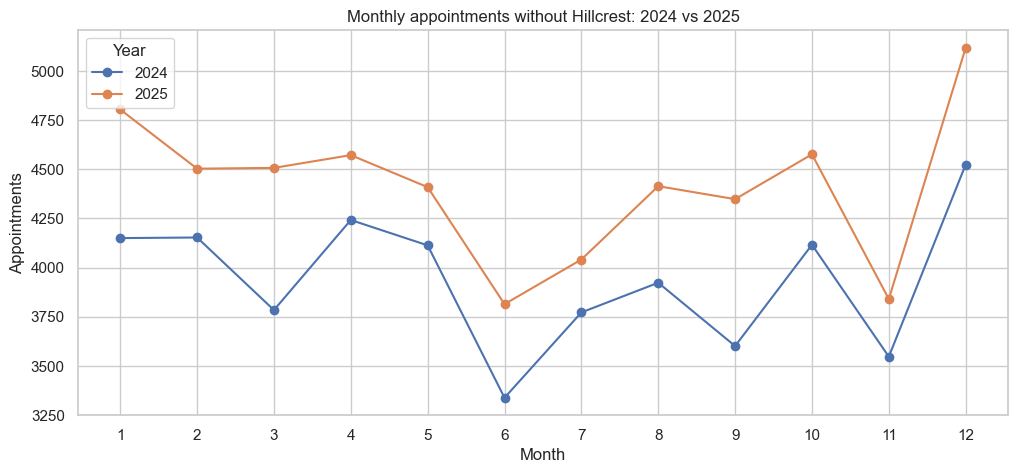

In [33]:
monthly_nh[[2024, 2025]].plot(marker="o")
plt.title("Monthly appointments without Hillcrest: 2024 vs 2025")
plt.xlabel("Month")
plt.ylabel("Appointments")
plt.xticks(range(1, 13))
plt.show()

# Q1: What Is Behind the Rise?

In [34]:
no_hill = df[df["ClinicName"] != "Nexora Care - Hillcrest"]
patients = no_hill.groupby("Year").agg(Appointments=("AppointmentID", "count"), Patients=("PatientID", "nunique"))
patients["Visits per patient"] = patients["Appointments"] / patients["Patients"]
patients.round(2)

,Appointments,Patients,Visits per patient
Year,,,
2024,47263,4935,9.58
2025,52946,4986,10.62


In [35]:
type_mix = no_hill.groupby(["AppointmentType", "Year"]).size().unstack()
type_mix["Change %"] = (type_mix[2025] / type_mix[2024] - 1) * 100
type_mix.round(1)

Year,2024,2025,Change %
AppointmentType,,,
Follow-Up,21160,23658,11.8
New Patient,8136,9128,12.2
Telehealth,11382,12966,13.9
Urgent,6585,7194,9.2


In [36]:
channel_mix = no_hill.groupby(["BookingChannel", "Year"]).size().unstack()
channel_mix["Change %"] = (channel_mix[2025] / channel_mix[2024] - 1) * 100
channel_mix.round(1)

Year,2024,2025,Change %
BookingChannel,,,
Online,21128,24257,14.8
Phone,13797,15270,10.7
Referral,7823,8635,10.4
Walk-In,4515,4784,6.0


## Q1 Answer
Appointments rose about 12% from 2024 to 2025 at Riverside, Lakeside and Downtown Express, the three clinics open for both full years.
- The rise is not just Hillcrest opening: 2025 is above 2024 in every month even without it.
- It was not consistent: the gap is wider in some months than others.
- The rise came from existing patients booking more visits (9.6 to 10.6 visits per patient). The number of patients grew only about 1%.
- Every appointment type grew by 9% to 14%, and every booking channel by 6% to 15%. Online grew fastest.
- The data cannot show why patients visit more often. That would need information from outside this file.

# Q2: Weekday and Month Patterns

daily table

In [37]:
daily = df.groupby(["ClinicName", "Date"]).size().reset_index(name="Appointments")
daily["DayOfWeek"] = daily["Date"].dt.day_name()
daily["Month"] = daily["Date"].dt.month

weekday pattern

In [38]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_avg = daily.groupby(["ClinicName", "DayOfWeek"])["Appointments"].mean().unstack()[day_order]
clinic_avg = daily.groupby("ClinicName")["Appointments"].mean()
weekday_pct = weekday_avg.div(clinic_avg, axis=0).sub(1).mul(100)
weekday_pct.round(1)

DayOfWeek,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
ClinicName,,,,,,,
Nexora Care - Downtown Express,7.1,18.9,13.6,9.0,5.4,-16.1,-38.2
Nexora Care - Hillcrest,7.3,22.2,20.1,12.8,5.0,-67.1,NaN
Nexora Care - Lakeside,2.3,18.5,11.0,8.7,-1.7,-39.0,NaN
Nexora Care - Riverside,8.2,22.6,16.6,11.0,3.5,-62.4,NaN


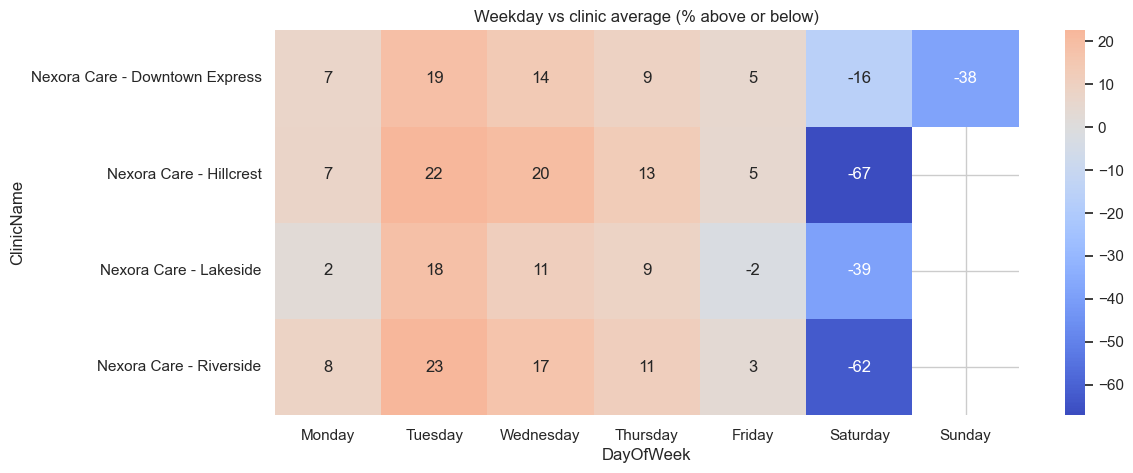

In [39]:
sns.heatmap(weekday_pct, annot=True, fmt=".0f", cmap="coolwarm", center=0)
plt.title("Weekday vs clinic average (% above or below)")
plt.show()

month pattern

In [40]:
month_avg = daily.groupby(["ClinicName", "Month"])["Appointments"].mean().unstack()
month_pct = month_avg.div(clinic_avg, axis=0).sub(1).mul(100)
month_pct.round(1)

Month,1,2,3,4,5,6,7,8,9,10,11,12
ClinicName,,,,,,,,,,,,
Nexora Care - Downtown Express,-9.6,-2.3,-5.6,0.4,-1.9,-7.4,-3.9,4.3,1.6,9.9,1.4,12.8
Nexora Care - Hillcrest,19.1,13.7,-1.5,13.7,1.4,2.4,-7.8,-8.4,-5.2,-2.4,-13.2,12.8
Nexora Care - Lakeside,7.0,13.5,0.8,8.0,-2.0,-11.6,-10.9,-1.8,-1.8,-0.3,-12.6,12.0
Nexora Care - Riverside,11.3,17.2,1.0,8.7,1.7,-13.7,-10.7,-6.5,-7.8,-4.1,-14.3,17.2


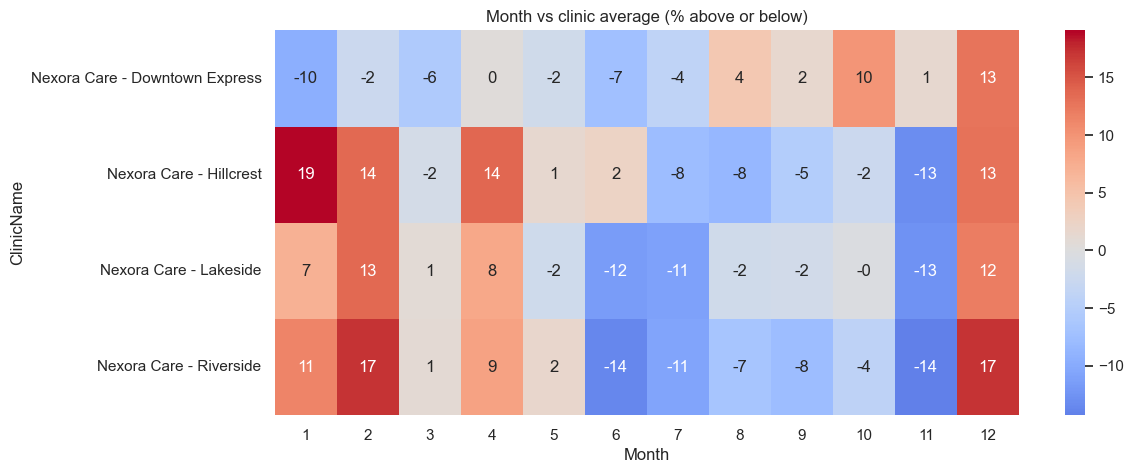

In [41]:
sns.heatmap(month_pct, annot=True, fmt=".0f", cmap="coolwarm", center=0)
plt.title("Month vs clinic average (% above or below)")
plt.show()

# Q3: Demand Across Clinics

In [42]:
clinic_summary = df.groupby("ClinicName").agg(
    Appointments=("AppointmentID", "count"),
    Open_days=("Date", "nunique"),
    Providers=("ProviderID", "nunique"),
)
clinic_summary["Share %"] = clinic_summary["Appointments"] / clinic_summary["Appointments"].sum() * 100
clinic_summary["Per open day"] = clinic_summary["Appointments"] / clinic_summary["Open_days"]
clinic_summary["Per provider per day"] = clinic_summary["Per open day"] / clinic_summary["Providers"]
clinic_summary.round(1)

,Appointments,Open_days,Providers,Share %,Per open day,Per provider per day
ClinicName,,,,,,
Nexora Care - Downtown Express,25146,731,6,19.4,34.4,5.7
Nexora Care - Hillcrest,29143,472,6,22.5,61.7,10.3
Nexora Care - Lakeside,45681,627,6,35.3,72.9,12.1
Nexora Care - Riverside,29382,627,6,22.7,46.9,7.8


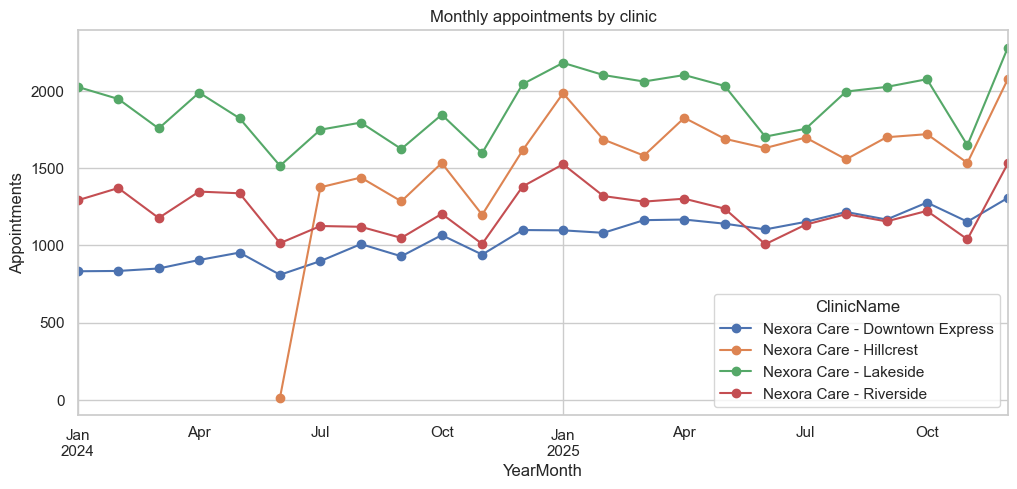

In [43]:
df["YearMonth"] = df["Date"].dt.to_period("M").dt.to_timestamp()
clinic_month = df.groupby(["YearMonth", "ClinicName"]).size().unstack()
clinic_month.plot(marker="o")
plt.title("Monthly appointments by clinic")
plt.ylabel("Appointments")
plt.show()

In [44]:
clinic_month.idxmax(axis=1).value_counts()

Nexora Care - Lakeside    24
Name: count, dtype: int64

# Q4: Cancellations and No-Shows

In [45]:
df["Lost"] = df["Status"] != "Completed"
df["Lost"].mean() * 100

np.float64(15.703661327231123)

In [46]:
status_share = pd.crosstab(df["ClinicName"], df["Status"], normalize="index") * 100
status_share.round(1)

Status,Cancelled,Completed,No-Show,Rescheduled
ClinicName,,,,
Nexora Care - Downtown Express,4.8,84.5,8.6,2.0
Nexora Care - Hillcrest,4.9,84.2,8.8,2.1
Nexora Care - Lakeside,4.8,84.4,8.8,2.0
Nexora Care - Riverside,5.0,84.1,8.8,2.1


In [47]:
lost_weekday = df.groupby(["ClinicName", "DayOfWeek"])["Lost"].mean().unstack()[day_order] * 100
lost_weekday.round(1)

DayOfWeek,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
ClinicName,,,,,,,
Nexora Care - Downtown Express,15.0,15.5,15.1,15.4,15.9,16.6,15.2
Nexora Care - Hillcrest,15.6,16.2,16.1,15.9,15.3,14.8,NaN
Nexora Care - Lakeside,15.8,15.6,15.4,15.6,15.8,15.7,NaN
Nexora Care - Riverside,15.5,16.1,16.4,15.2,15.9,16.7,NaN


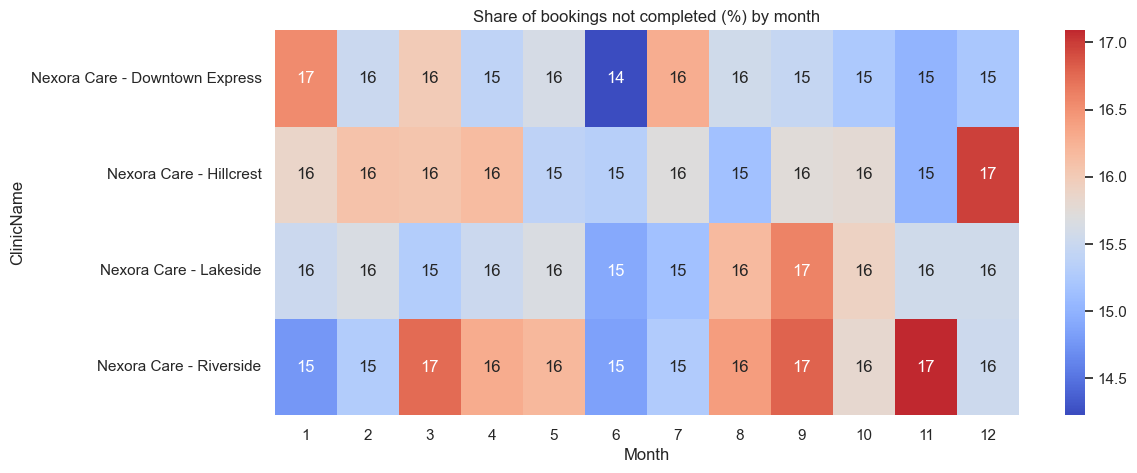

In [48]:
lost_month = df.groupby(["ClinicName", "Month"])["Lost"].mean().unstack() * 100
sns.heatmap(lost_month, annot=True, fmt=".0f", cmap="coolwarm", center=lost_month.values.mean())
plt.title("Share of bookings not completed (%) by month")
plt.show()

In [49]:
pd.crosstab(df["AppointmentType"], df["Status"], normalize="index").mul(100).round(1)

Status,Cancelled,Completed,No-Show,Rescheduled
AppointmentType,,,,
Follow-Up,4.9,84.3,8.7,2.0
New Patient,5.0,83.0,9.9,2.1
Telehealth,4.8,84.5,8.6,2.0
Urgent,4.8,85.2,8.0,2.0


In [50]:
pd.crosstab(df["BookingChannel"], df["Status"], normalize="index").mul(100).round(1)

Status,Cancelled,Completed,No-Show,Rescheduled
BookingChannel,,,,
Online,4.8,84.3,8.8,2.1
Phone,4.9,84.4,8.7,2.0
Referral,5.0,84.1,8.9,2.0
Walk-In,5.0,84.2,8.7,2.0


## Q4 Answer
- About 15.7% of bookings are not completed: roughly 8.8% no-shows, 4.9% cancellations and 2.0% reschedules.
- The share is almost identical across clinics (84.1% to 84.5% completed), weekdays (14.8% to 16.7% not completed), months (14% to 17%) and booking channels.
- The one pattern worth noting: New Patient bookings have the highest no-show rate (9.9%) and Urgent the lowest (8.0%).
- Because the rate is so steady, counting all bookings or completed only gives the same weekly shape, with completed volume about 16% lower.
- The data does not explain why patients miss appointments.

# Q5: Booking Lead Time and Attendance

In [51]:
bins = [-1, 0, 3, 7, 14, 30, 60]
labels = ["Same day", "1-3 days", "4-7 days", "8-14 days", "15-30 days", "31-60 days"]
df["LeadBand"] = pd.cut(df["BookingLeadTimeDays"], bins=bins, labels=labels)
df["LeadBand"].value_counts().sort_index()

LeadBand
Same day       3944
1-3 days      33269
4-7 days      32224
8-14 days     36691
15-30 days    20777
31-60 days     2447
Name: count, dtype: int64

In [52]:
lead_status = pd.crosstab(df["LeadBand"], df["Status"], normalize="index").mul(100)
lead_status.round(1)

Status,Cancelled,Completed,No-Show,Rescheduled
LeadBand,,,,
Same day,4.5,86.0,7.8,1.7
1-3 days,4.8,85.3,7.9,2.0
4-7 days,4.9,85.0,8.1,2.0
8-14 days,4.9,84.5,8.5,2.1
15-30 days,4.9,82.0,11.0,2.1
31-60 days,5.3,75.5,17.2,2.1


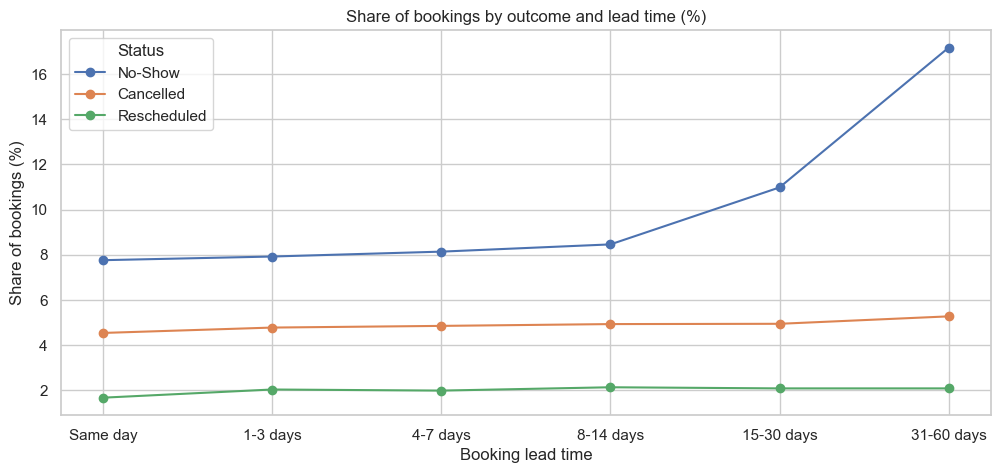

In [53]:
lead_status[["No-Show", "Cancelled", "Rescheduled"]].plot(marker="o")
plt.title("Share of bookings by outcome and lead time (%)")
plt.xlabel("Booking lead time")
plt.ylabel("Share of bookings (%)")
plt.show()

In [54]:
df.groupby("Status")["BookingLeadTimeDays"].agg(["mean", "median"]).round(1)

,mean,median
Status,,
Cancelled,8.8,7.0
Completed,8.6,7.0
No-Show,10.0,8.0
Rescheduled,8.9,7.0
